# 09 - WA-TGCN v2 (accuracy push)

Separate from `07_final_model.ipynb`. 07's models, config, metrics and the dashboard
export are left untouched so v1 vs v2 can be compared directly.

All changes are historical-only (no forecast weather, no test-set tuning). Everything
is selected on the **validation** set; test is scored once at the end.

1. Richer historical features (14 -> 26): cyclical time (sin/cos of hour/day/month),
   6h/24h rolling mean & std of PM2.5 (explicit volatility signal), 3h delta,
   wind-speed magnitude, regional context (city mean/max PM2.5, station-minus-city).
2. Forecast-graph decoder: a 2nd wind-aware adjacency A_fc from a train-only wind
   climatology (mean u/v per station per month-hour), used to propagate the encoder
   context spatially across the 24 forecast hours. Direct answer to 07's documented
   limitation ('only ever sees historical wind'), no external data.
3. 2-hop GCN encoder (was 1 hop).
4. Volatility-weighted Huber loss - up-weights high-swing training windows, the
   regime holding 78% of v1's total error.
5. 7-seed ensemble (was 5), cosine LR schedule with warmup.

Memory note: v2 does NOT load the windowed `At_*.npy` files. It slices
`dynamic_adj_matrix.npy` (T,37,37) by window index - verified identical to
`At_train[i] == dynamic_adj[i:i+48]`.

In [1]:
import os, json, time, copy, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

BASE   = r'D:\FYP\Eco-Twin'
V2_DIR = os.path.join(BASE, 'v2_clean')
OUT    = os.path.join(V2_DIR, 'ecotwin_outputs')
SCALER_DIR, PLOT_DIR   = os.path.join(OUT, 'scalers'), os.path.join(OUT, 'plots')
MODEL_DIR, RESULTS_DIR = os.path.join(OUT, 'models'),  os.path.join(OUT, 'results')

DATASET_CSV      = os.path.join(V2_DIR, 'EcoTwin_Final_Dataset.csv')
DYNAMIC_ADJ_PATH = os.path.join(V2_DIR, 'dynamic_adj_matrix.npy')
STATIONS_EXCEL   = os.path.join(V2_DIR, 'Delhi_list_v2.xlsx')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

INPUT_WINDOW, HORIZON = 48, 24
BATCH_SIZE = 16
HIDDEN_DIM, GRU_LAYERS, ATTN_HEADS, DROPOUT = 32, 1, 4, 0.2
GCN_HOPS       = 2
LOSS_VOL_ALPHA = 1.0                       # volatility up-weighting (0 = plain Huber)
SEEDS          = [42, 7, 123, 2024, 999, 2025, 77]
THRESHOLD_KM   = 12.0
V2_TAG         = 'watgcn_v2'               # 07's files are never overwritten

print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU   : {torch.cuda.get_device_name(0)}')
print(f'Seeds : {SEEDS}')

# HOW TO CHECK: should print 'cuda' + your RTX 3050. 'cpu' still works, ~10x slower.

Device: cuda
GPU   : NVIDIA GeForce RTX 3050 6GB Laptop GPU
Seeds : [42, 7, 123, 2024, 999, 2025, 77]


In [2]:
df = pd.read_csv(DATASET_CSV, parse_dates=['Timestamp'])
df['Station'] = df['Station'].str.strip()
df = df.sort_values(['Station', 'Timestamp']).reset_index(drop=True)

df_st = pd.read_excel(STATIONS_EXCEL)
df_st.columns = df_st.columns.str.strip().str.lower()
df_st['station'] = df_st['station'].str.strip()
station_names = df_st['station'].tolist()
lats = df_st['latitude'].values.astype(float)
lons = df_st['longitude'].values.astype(float)
N = len(station_names)

timestamps = np.array(sorted(df['Timestamp'].unique()))
T = len(timestamps)
dyn_adj = np.load(DYNAMIC_ADJ_PATH).astype(np.float32)          # (T,N,N) wind A(t), no self-loops
assert dyn_adj.shape == (T, N, N), (dyn_adj.shape, (T, N, N))

print(f'Stations   : {N}')
print(f'Timestamps : {T:,}  ({timestamps[0]} -> {timestamps[-1]})')
print(f'dyn_adj    : {dyn_adj.shape}  {dyn_adj.nbytes/1e6:.0f} MB')

# geometry for the forecast-climatology graph (same recipe as 03_dynamic_adjacency)
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dlmb/2)**2
    return 2*R*np.arctan2(np.sqrt(a), np.sqrt(1-a))

dist_matrix = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        if i != j:
            dist_matrix[i, j] = haversine_km(lats[i], lons[i], lats[j], lons[j])
within_threshold = (dist_matrix > 0) & (dist_matrix <= THRESHOLD_KM)
dir_u = np.zeros((N, N)); dir_v = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        if i != j:
            de = (lons[j]-lons[i]) * np.cos(np.radians(lats[i]))
            dn = (lats[j]-lats[i])
            nrm = np.hypot(de, dn)
            if nrm > 0:
                dir_u[i, j], dir_v[i, j] = de/nrm, dn/nrm
print(f'Edges within {THRESHOLD_KM} km: {int(within_threshold.sum())}')

# HOW TO CHECK: 'Edges within 12 km' matches 03_dynamic_adjacency. dyn_adj ~105 MB.

Stations   : 37
Timestamps : 19,921  (2024-01-01 00:00:00 -> 2026-04-10 00:00:00)
dyn_adj    : (19921, 37, 37)  109 MB
Edges within 12.0 km: 508


In [3]:
BASE_FEATS = ['pm2.5','pm10','no2','so2','co','o3','rh','at','u_wind','v_wind']
g = df.groupby('Station', sort=False)

df['wspd'] = np.hypot(df['u_wind'], df['v_wind'])

# rolling PM2.5 stats - window ends at 'now' (an observed hour), so no leakage
df['pm_roll6_mean']  = g['pm2.5'].transform(lambda s: s.rolling(6,  min_periods=1).mean())
df['pm_roll6_std']   = g['pm2.5'].transform(lambda s: s.rolling(6,  min_periods=1).std()).fillna(0.0)
df['pm_roll24_mean'] = g['pm2.5'].transform(lambda s: s.rolling(24, min_periods=1).mean())
df['pm_roll24_std']  = g['pm2.5'].transform(lambda s: s.rolling(24, min_periods=1).std()).fillna(0.0)
df['pm_delta3']      = g['pm2.5'].transform(lambda s: s - s.shift(3)).fillna(0.0)

tsg = df.groupby('Timestamp', sort=False)['pm2.5']
df['city_mean_pm']  = tsg.transform('mean')
df['city_max_pm']   = tsg.transform('max')
df['pm_minus_city'] = df['pm2.5'] - df['city_mean_pm']

hh  = df['Timestamp'].dt.hour; dow = df['Timestamp'].dt.dayofweek; mon = df['Timestamp'].dt.month
df['hour_sin'] = np.sin(2*np.pi*hh/24);      df['hour_cos'] = np.cos(2*np.pi*hh/24)
df['dow_sin']  = np.sin(2*np.pi*dow/7);      df['dow_cos']  = np.cos(2*np.pi*dow/7)
df['mon_sin']  = np.sin(2*np.pi*(mon-1)/12); df['mon_cos']  = np.cos(2*np.pi*(mon-1)/12)
df['is_weekend'] = (dow >= 5).astype(float)

FEATURE_COLS = (BASE_FEATS +
    ['wspd','pm_roll6_mean','pm_roll6_std','pm_roll24_mean','pm_roll24_std','pm_delta3',
     'city_mean_pm','city_max_pm','pm_minus_city',
     'hour_sin','hour_cos','dow_sin','dow_cos','mon_sin','mon_cos','is_weekend'])
F = len(FEATURE_COLS)
TIME_COLS = ['hour_sin','hour_cos','dow_sin','dow_cos','mon_sin','mon_cos','is_weekend']
TIME_IDX  = [FEATURE_COLS.index(c) for c in TIME_COLS]

X_full = np.zeros((T, N, F), dtype=np.float32)
for fi, col in enumerate(FEATURE_COLS):
    wide = df.pivot_table(index='Timestamp', columns='Station', values=col).reindex(columns=station_names)
    X_full[:, :, fi] = np.nan_to_num(wide.values.astype(np.float32))
Y_full = X_full[:, :, 0].copy()                                  # PM2.5 target (channel 0)

print(f'F = {F} features')
print(FEATURE_COLS)
print(f'X_full {X_full.shape}  {X_full.nbytes/1e6:.0f} MB   NaNs: {int(np.isnan(X_full).sum())}')

# HOW TO CHECK: F == 26, X_full ~77 MB, NaNs == 0.

F = 26 features
['pm2.5', 'pm10', 'no2', 'so2', 'co', 'o3', 'rh', 'at', 'u_wind', 'v_wind', 'wspd', 'pm_roll6_mean', 'pm_roll6_std', 'pm_roll24_mean', 'pm_roll24_std', 'pm_delta3', 'city_mean_pm', 'city_max_pm', 'pm_minus_city', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'mon_sin', 'mon_cos', 'is_weekend']
X_full (19921, 37, 26)  77 MB   NaNs: 0


In [4]:
train_end_idx = int(T * 0.70)                                    # 13944
val_end_idx   = int(T * 0.85)                                    # 16932

def split_starts(lo, hi):
    n = (hi - lo) - (INPUT_WINDOW + HORIZON) + 1                  # windows fully inside [lo,hi)
    return np.arange(lo, lo + n)

train_starts = split_starts(0, train_end_idx)
val_starts   = split_starts(train_end_idx, val_end_idx)
test_starts  = split_starts(val_end_idx, T)
print(f'windows -- train {len(train_starts):,} | val {len(val_starts):,} | test {len(test_starts):,}')

train_ts_mask = np.zeros(T, bool); train_ts_mask[:train_end_idx] = True

feat_scaler = StandardScaler().fit(X_full[train_ts_mask].reshape(-1, F))
Xs_full = feat_scaler.transform(X_full.reshape(-1, F)).reshape(T, N, F).astype(np.float32)

pm_train   = Y_full[train_ts_mask].reshape(-1, 1)
log_scaler = StandardScaler().fit(np.log1p(np.clip(pm_train, 0, None)))
def to_log(a):
    return log_scaler.transform(np.log1p(np.clip(a, 0, None)).reshape(-1, 1)).reshape(a.shape).astype(np.float32)
def from_log(a):
    return np.expm1(log_scaler.inverse_transform(a.reshape(-1, 1)).reshape(a.shape))
Yl_full = to_log(Y_full)                                         # anchor = Yl_full[now] later

_std = Xs_full[train_ts_mask].reshape(-1, F).std(0)
print(f'raw PM2.5 skew {pd.Series(pm_train.ravel()).skew():.2f} -> log skew '
      f'{pd.Series(np.log1p(pm_train.ravel())).skew():.2f}')
print(f'per-feature std after scaling: min {_std.min():.2f}  max {_std.max():.2f}')

del X_full                                                       # free RAM - only Xs_full needed now

# HOW TO CHECK: window counts 13873 / 2917 / 2918 (same as 07). log skew ~0. std ~1.

windows -- train 13,873 | val 2,917 | test 2,918
raw PM2.5 skew 2.56 -> log skew -0.18
per-feature std after scaling: min 1.00  max 1.00


In [5]:
# forecast-horizon adjacency from a TRAIN-only wind climatology
def compute_At_vec(u, v, eps=1e-6):
    align = u[:, None]*dir_u + v[:, None]*dir_v                  # wind at i . direction(i->j)
    A = np.where(within_threshold & (align > 0.0), align/(dist_matrix + eps), 0.0).astype(np.float32)
    rs = A.sum(1, keepdims=True); rs[rs == 0] = 1.0
    return A / rs

trm = df['Timestamp'].isin(pd.DatetimeIndex(timestamps[:train_end_idx]))
cl = (df[trm].assign(mo=df.loc[trm, 'Timestamp'].dt.month - 1,
                     ho=df.loc[trm, 'Timestamp'].dt.hour)
             .groupby(['Station', 'mo', 'ho'])[['u_wind', 'v_wind']].mean())
st_mean = df[trm].groupby('Station')[['u_wind', 'v_wind']].mean()
cl_idx = set(cl.index)

clim_grid = np.zeros((12, 24, N, 2), dtype=np.float32)           # (month, hour, station, uv)
for si, s in enumerate(station_names):
    for mo in range(12):
        for ho in range(24):
            clim_grid[mo, ho, si] = (cl.loc[(s, mo, ho)].values
                                     if (s, mo, ho) in cl_idx else st_mean.loc[s].values)

mo_arr = pd.DatetimeIndex(timestamps).month.values - 1
ho_arr = pd.DatetimeIndex(timestamps).hour.values
t0 = time.time()
dyn_clim = np.zeros((T, N, N), dtype=np.float32)
for t in range(T):
    uv = clim_grid[mo_arr[t], ho_arr[t]]
    dyn_clim[t] = compute_At_vec(uv[:, 0], uv[:, 1])
print(f'dyn_clim {dyn_clim.shape} built in {time.time()-t0:.0f}s  ({dyn_clim.nbytes/1e6:.0f} MB)')
print(f'edges/hr -- hourly A(t) {np.mean((dyn_adj>0).sum((1,2))):.1f} | '
      f'climatology {np.mean((dyn_clim>0).sum((1,2))):.1f}')

import gc; del df, trm, cl; gc.collect()                         # free RAM - df no longer needed

# HOW TO CHECK: climatology edges/hr in the same ballpark as hourly (smoother). <60s.

dyn_clim (19921, 37, 37) built in 0s  (109 MB)
edges/hr -- hourly A(t) 259.6 | climatology 264.1


1104

In [6]:
class EcoWindowDS(Dataset):
    """Slices the shared full-length arrays by window-start index - no windowed copies."""
    def __init__(self, starts, weights=None):
        self.s = np.asarray(starts, dtype=np.int64)
        self.w = (weights if weights is not None else np.ones(len(self.s), np.float32)).astype(np.float32)
    def __len__(self):
        return len(self.s)
    def __getitem__(self, k):
        gg = int(self.s[k]); i1 = gg + INPUT_WINDOW; i2 = i1 + HORIZON
        return (torch.from_numpy(Xs_full[gg:i1].copy()),           # (48,N,F)
                torch.from_numpy(dyn_adj[gg:i1].copy()),           # (48,N,N)
                torch.from_numpy(dyn_clim[i1:i2].copy()),          # (24,N,N)
                torch.from_numpy(Xs_full[i1:i2, 0, :][:, TIME_IDX].copy()),  # (24,n_time)
                torch.from_numpy(Yl_full[i1-1].copy()),            # (N,) last obs PM2.5 (log)
                torch.from_numpy(Yl_full[i1:i2].copy()),           # (24,N) target (log)
                torch.tensor(self.w[k], dtype=torch.float32))

def window_swing(starts):
    sw = np.empty(len(starts), np.float32)
    for k, gg in enumerate(starts):
        seg = Y_full[gg+INPUT_WINDOW : gg+INPUT_WINDOW+HORIZON]
        sw[k] = (seg.max(0) - seg.min(0)).mean()
    return sw

tr_swing = window_swing(train_starts)
med = float(np.median(tr_swing))
tr_w = 1.0 + LOSS_VOL_ALPHA * (tr_swing / (med + 1e-6))
tr_w = np.clip(tr_w, 0.5, 4.0).astype(np.float32)
tr_w *= len(tr_w) / tr_w.sum()
print(f'train swing: median {med:.1f}  p90 {np.percentile(tr_swing,90):.1f}')
print(f'loss weights: min {tr_w.min():.2f}  mean {tr_w.mean():.2f}  max {tr_w.max():.2f}')

train_ld = DataLoader(EcoWindowDS(train_starts, tr_w), batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_ld   = DataLoader(EcoWindowDS(val_starts),         batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_ld  = DataLoader(EcoWindowDS(test_starts),        batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f'batches -- train {len(train_ld)} | val {len(val_ld)} | test {len(test_ld)}')

train swing: median 107.4  p90 224.5
loss weights: min 0.56  mean 1.00  max 1.87
batches -- train 868 | val 183 | test 183


In [7]:
class WATGCNv2(nn.Module):
    def __init__(self, in_features, hidden_dim, gru_layers, attn_heads,
                 forecast_horizon, n_stations, dropout=0.2, n_time=7, gcn_hops=2):
        super().__init__()
        H = hidden_dim
        self.input_proj = nn.Linear(in_features, H)
        self.gcn_lin  = nn.ModuleList(nn.Linear(H, H) for _ in range(gcn_hops))
        self.gcn_norm = nn.ModuleList(nn.LayerNorm(H) for _ in range(gcn_hops))
        self.act = nn.ReLU()
        self.gru = nn.GRU(H, H, gru_layers, batch_first=True,
                          dropout=dropout if gru_layers > 1 else 0.0)
        self.attn = nn.MultiheadAttention(H, attn_heads, dropout=dropout, batch_first=True)
        self.attn_norm = nn.LayerNorm(H)
        self.dropout = nn.Dropout(dropout)
        self.time_enc = nn.Sequential(nn.Linear(n_time, H), nn.ReLU(), nn.Linear(H, H))
        self.decoder = nn.Sequential(nn.Linear(H*3, H), nn.ReLU(), nn.Dropout(dropout), nn.Linear(H, 1))
        self.anchor_gate = nn.Parameter(torch.linspace(1.0, 0.3, forecast_horizon))
        self.H, self.FH = H, forecast_horizon

    @staticmethod
    def _norm_adj(A, n, device):
        I = torch.eye(n, device=device).unsqueeze(0).unsqueeze(0)
        A = A + I
        return A / A.sum(-1, keepdim=True).clamp(min=1e-6)

    def forward(self, X, At, Afc, TFut, Anchor):
        B, Tin, n, _ = X.shape
        h = self.act(self.input_proj(X))                          # (B,Tin,n,H)
        A = self._norm_adj(At, n, X.device)
        for lin, nrm in zip(self.gcn_lin, self.gcn_norm):
            h = self.act(nrm(lin(torch.matmul(A, h)))) + h        # residual graph hop
        hf = h.permute(0, 2, 1, 3).reshape(B*n, Tin, self.H)
        gg, _ = self.gru(hf)
        gg = self.dropout(gg)
        aa, _ = self.attn(gg, gg, gg)
        ctx = self.attn_norm(aa + gg)[:, -1, :].reshape(B, n, self.H)   # (B,n,H)
        Afc_n = self._norm_adj(Afc, n, X.device)                  # (B,FH,n,n)
        ctx_fc = torch.matmul(Afc_n, ctx.unsqueeze(1).expand(B, self.FH, n, self.H))  # (B,FH,n,H)
        t_emb = self.time_enc(TFut).unsqueeze(2).expand(B, self.FH, n, self.H)
        ctx_rep = ctx.unsqueeze(1).expand(B, self.FH, n, self.H)
        resid = self.decoder(torch.cat([ctx_rep, ctx_fc, t_emb], dim=-1)).squeeze(-1)  # (B,FH,n)
        anchor = Anchor.unsqueeze(1) * self.anchor_gate.view(1, self.FH, 1)
        return resid + anchor

_m = WATGCNv2(F, HIDDEN_DIM, GRU_LAYERS, ATTN_HEADS, HORIZON, N, DROPOUT, len(TIME_IDX), GCN_HOPS)
print(f'v2 parameters: {sum(p.numel() for p in _m.parameters()):,}')
del _m

v2 parameters: 18,201


In [8]:
def weighted_huber(pred, target, w, delta=1.0):
    absr = (pred - target).abs()
    quad = torch.clamp(absr, max=delta)
    per = (0.5*quad**2 + delta*(absr - quad)).mean(dim=(1, 2))    # (B,)
    return (per * w).mean() / w.mean().clamp(min=1e-6)

def run_epoch(model, loader, opt=None, sched=None):
    is_train = opt is not None
    model.train(is_train)
    tot, n = 0.0, 0
    for X, At, Afc, tf, anc, y, w in loader:
        X, At, Afc = X.to(DEVICE), At.to(DEVICE), Afc.to(DEVICE)
        tf, anc, y, w = tf.to(DEVICE), anc.to(DEVICE), y.to(DEVICE), w.to(DEVICE)
        with torch.set_grad_enabled(is_train):
            out = model(X, At, Afc, tf, anc)
            loss = weighted_huber(out, y, w if is_train else torch.ones_like(w))
        if is_train:
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            if sched is not None: sched.step()
        tot += loss.item() * X.size(0); n += X.size(0)
    return tot / n

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, A = [], []
    for X, At, Afc, tf, anc, y, w in loader:
        out = model(X.to(DEVICE), At.to(DEVICE), Afc.to(DEVICE), tf.to(DEVICE), anc.to(DEVICE))
        P.append(out.cpu().numpy()); A.append(y.numpy())
    return np.concatenate(P), np.concatenate(A)

def score(pred_log, act_log):
    pr, ar = from_log(pred_log), from_log(act_log)
    return dict(rmse=float(np.sqrt(mean_squared_error(ar.ravel(), pr.ravel()))),
                mae=float(mean_absolute_error(ar.ravel(), pr.ravel())),
                r2=float(r2_score(ar.ravel(), pr.ravel())), preds=pr, actual=ar)

def train_model(seed, max_epochs=60, patience=12, lr=1e-3, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    model = WATGCNv2(F, HIDDEN_DIM, GRU_LAYERS, ATTN_HEADS, HORIZON, N,
                     DROPOUT, len(TIME_IDX), GCN_HOPS).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = len(train_ld) * max_epochs
    warm = max(1, int(0.05 * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: s/warm if s < warm else
        0.5*(1 + np.cos(np.pi*(s-warm)/max(1, steps-warm))))
    best, best_state, ctr = 1e9, None, 0
    hist = {'train': [], 'val': []}
    for ep in range(1, max_epochs+1):
        t0 = time.time()
        tr = run_epoch(model, train_ld, opt, sched)
        vl = run_epoch(model, val_ld)
        hist['train'].append(tr); hist['val'].append(vl)
        if vl < best - 1e-5:
            best, best_state, ctr = vl, copy.deepcopy(model.state_dict()), 0
            tag = 'best'
        else:
            ctr += 1; tag = f'{ctr}/{patience}'
        if verbose:
            print(f'  ep {ep:>2} | train {tr:.5f} | val {vl:.5f} | {time.time()-t0:>4.0f}s | {tag}')
        if ctr >= patience:
            break
    model.load_state_dict(best_state)
    return model, best, hist

print('train / predict / score / train_model ready.')

train / predict / score / train_model ready.


In [9]:
# smoke test: 3 epochs, seed 42 - proves the path runs and loss drops
_m, _b, _h = train_model(42, max_epochs=3, patience=99)
_p, _a = predict(_m, val_ld)
print('val (3 ep) ->', {k: round(v, 3) for k, v in score(_p, _a).items() if k in ('rmse','mae','r2')})
del _m

# HOW TO CHECK: val loss falls each epoch; RMSE ~70-85 after only 3 epochs (not final).
# NaN or flat loss -> stop.

  ep  1 | train 0.16299 | val 0.14035 |   19s | best
  ep  2 | train 0.13600 | val 0.14499 |   19s | 1/99
  ep  3 | train 0.13052 | val 0.13817 |   20s | best
val (3 ep) -> {'rmse': 56.166, 'mae': 31.877, 'r2': 0.728}


In [10]:
# leakage sanity check: persistence baseline (predict "last observed", repeated 24h)
# on the SAME pipeline. Must land in the normal ~72-88 RMSE range.
# If it comes out near the model's 56, the eval harness is leaking and we stop.
Pp, Ap = [], []
for X, At, Afc, tf, anc, y, w in val_ld:
    Pp.append(anc.unsqueeze(1).expand(-1, HORIZON, -1).numpy())
    Ap.append(y.numpy())
pers = score(np.concatenate(Pp), np.concatenate(Ap))
print(f"persistence baseline  val RMSE {pers['rmse']:.1f} | MAE {pers['mae']:.1f} | R2 {pers['r2']:.3f}")
print(f"smoke model (3ep)     val RMSE 56.2")
print(f"v1 / 07 final         test RMSE 64.6")

# also confirm the model isn't just copying the anchor
d = np.abs(np.concatenate(Pp) - _p).mean()
print(f"mean |pred - anchor| (log space): {d:.3f}   (~0 would mean the model does nothing)")

persistence baseline  val RMSE 81.5 | MAE 44.8 | R2 0.428
smoke model (3ep)     val RMSE 56.2
v1 / 07 final         test RMSE 64.6
mean |pred - anchor| (log space): 0.375   (~0 would mean the model does nothing)


In [11]:
models, val_scores, hists, val_preds = [], [], [], []
for sd in SEEDS:
    print(f'\n=== seed {sd} ===')
    m, b, h = train_model(sd)
    p, a = predict(m, val_ld)
    models.append(m); val_scores.append(b); hists.append(h); val_preds.append(p)
    sv = score(p, a)
    print(f"  seed {sd}: val_huber {b:.5f} | val RMSE {sv['rmse']:.2f} | R2 {sv['r2']:.3f}")
val_actual = a
print(f'\nper-seed val RMSE: {[round(score(p, val_actual)["rmse"], 2) for p in val_preds]}')


=== seed 42 ===
  ep  1 | train 0.20381 | val 0.15227 |   19s | best
  ep  2 | train 0.15092 | val 0.14545 |   18s | best
  ep  3 | train 0.13817 | val 0.15227 |   18s | 1/12
  ep  4 | train 0.13267 | val 0.14971 |   19s | 2/12
  ep  5 | train 0.12731 | val 0.13336 |   19s | best
  ep  6 | train 0.12298 | val 0.14511 |   19s | 1/12
  ep  7 | train 0.11909 | val 0.13631 |   19s | 2/12
  ep  8 | train 0.11573 | val 0.14081 |   19s | 3/12
  ep  9 | train 0.11211 | val 0.14478 |   19s | 4/12
  ep 10 | train 0.10923 | val 0.14791 |   19s | 5/12
  ep 11 | train 0.10593 | val 0.14590 |   19s | 6/12
  ep 12 | train 0.10433 | val 0.15098 |   19s | 7/12
  ep 13 | train 0.10172 | val 0.15095 |   19s | 8/12
  ep 14 | train 0.10012 | val 0.14704 |   19s | 9/12
  ep 15 | train 0.09806 | val 0.15316 |   19s | 10/12
  ep 16 | train 0.09691 | val 0.15155 |   19s | 11/12
  ep 17 | train 0.09534 | val 0.15546 |   18s | 12/12
  seed 42: val_huber 0.13336 | val RMSE 56.87 | R2 0.721

=== seed 7 ===
  ep  

In [12]:
# ensemble: pick on VALIDATION, then score TEST once
val_ens = score(np.mean(val_preds, axis=0), val_actual)

test_pred_seeds, test_actual = [], None
for m in models:
    p, a = predict(m, test_ld); test_pred_seeds.append(p); test_actual = a
test_ens = score(np.mean(test_pred_seeds, axis=0), test_actual)

with open(os.path.join(RESULTS_DIR, 'final_metrics.json')) as f:
    v1 = json.load(f)

print(f"{'':14}{'v1 07':>10}{'v2 val':>10}{'v2 test':>10}")
print(f"{'RMSE':14}{v1['rmse']:>10.2f}{val_ens['rmse']:>10.2f}{test_ens['rmse']:>10.2f}")
print(f"{'MAE':14}{v1['mae']:>10.2f}{val_ens['mae']:>10.2f}{test_ens['mae']:>10.2f}")
print(f"{'R2':14}{v1['r2']:>10.3f}{val_ens['r2']:>10.3f}{test_ens['r2']:>10.3f}")

                   v1 07    v2 val   v2 test
RMSE               64.59     55.14     60.92
MAE                41.50     30.43     39.69
R2                 0.589     0.738     0.634


In [13]:
pr, ar = test_ens['preds'], test_ens['actual']
h_rmse = [float(np.sqrt(mean_squared_error(ar[:, h, :].ravel(), pr[:, h, :].ravel()))) for h in range(HORIZON)]
print('RMSE by horizon (v1 -> v2):')
for h in [0, 5, 11, 17, 23]:
    print(f"  +{h+1:>2}h : {v1['rmse_by_horizon'][f'+{h+1}h']:>6.1f}  ->  {h_rmse[h]:>6.1f}")

swing = ar.max(1) - ar.min(1)
q33, q66 = np.percentile(swing, [33, 66])
reg = {'Stable': swing <= q33, 'Moderate': (swing > q33) & (swing <= q66), 'Volatile': swing > q66}
sq = ((ar - pr)**2).transpose(0, 2, 1); tot = sq.sum()
print(f"\n{'regime':10}{'v1 RMSE':>10}{'v2 RMSE':>10}{'v2 %err':>10}")
reg_rmse = {}
for k, msk in reg.items():
    a_, p_ = ar.transpose(0, 2, 1)[msk], pr.transpose(0, 2, 1)[msk]
    reg_rmse[k] = float(np.sqrt(((a_ - p_)**2).mean()))
    print(f"{k:10}{v1['rmse_by_regime'][k]:>10.2f}{reg_rmse[k]:>10.2f}{sq[msk].sum()/tot*100:>9.1f}%")

RMSE by horizon (v1 -> v2):
  + 1h :   43.0  ->    41.4
  + 6h :   61.1  ->    56.7
  +12h :   67.0  ->    63.0
  +18h :   69.8  ->    66.0
  +24h :   69.4  ->    66.5

regime       v1 RMSE   v2 RMSE   v2 %err
Stable         28.11     29.89      7.9%
Moderate       44.78     42.95     16.4%
Volatile       97.76     90.87     75.7%


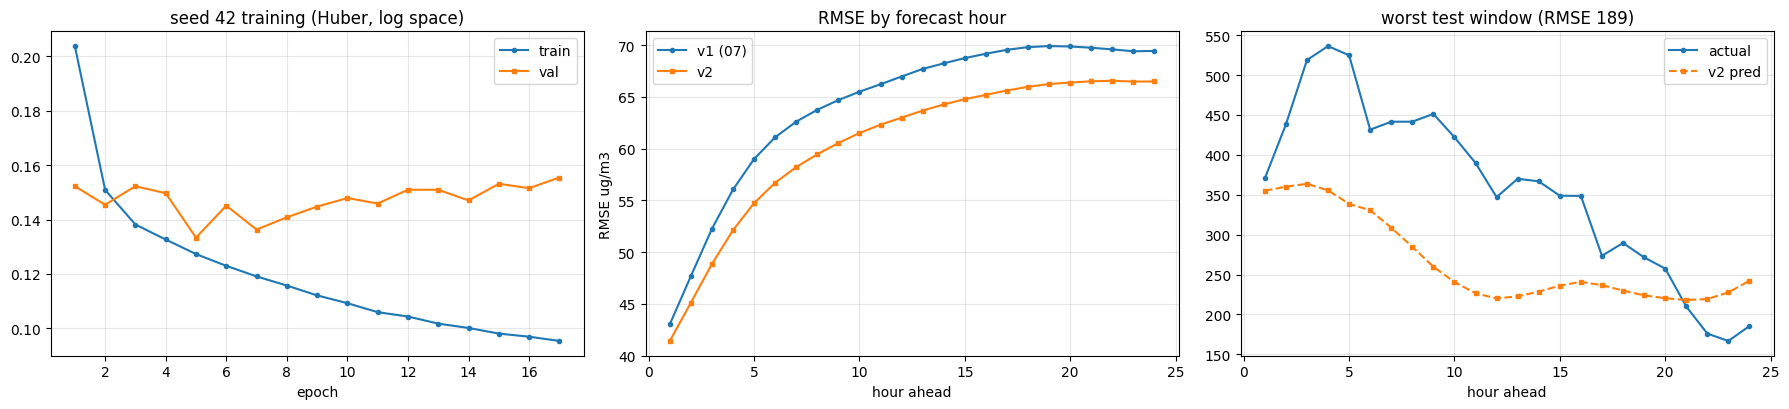

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
ax[0].plot(range(1, len(hists[0]['train'])+1), hists[0]['train'], marker='o', ms=3, label='train')
ax[0].plot(range(1, len(hists[0]['val'])+1),   hists[0]['val'],   marker='s', ms=3, label='val')
ax[0].set_title(f'seed {SEEDS[0]} training (Huber, log space)'); ax[0].set_xlabel('epoch')
ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(range(1, 25), [v1['rmse_by_horizon'][f'+{h+1}h'] for h in range(24)], marker='o', ms=3, label='v1 (07)')
ax[1].plot(range(1, 25), h_rmse, marker='s', ms=3, label='v2')
ax[1].set_title('RMSE by forecast hour'); ax[1].set_xlabel('hour ahead'); ax[1].set_ylabel('RMSE ug/m3')
ax[1].legend(); ax[1].grid(alpha=.3)

wr = np.sqrt(((ar - pr)**2).mean(axis=(1, 2)))
wi = int(wr.argmax())
ax[2].plot(range(1, 25), ar[wi, :, 0], marker='o', ms=3, label='actual')
ax[2].plot(range(1, 25), pr[wi, :, 0], marker='s', ms=3, ls='--', label='v2 pred')
ax[2].set_title(f'worst test window (RMSE {wr[wi]:.0f})'); ax[2].set_xlabel('hour ahead')
ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'v2_summary.png'), dpi=150, bbox_inches='tight')
plt.show()

In [15]:
v1_ps = pd.read_csv(os.path.join(RESULTS_DIR, 'final_per_station.csv')).set_index('Station')
rows = []
for n in range(N):
    a_, p_ = ar[:, :, n].ravel(), pr[:, :, n].ravel()
    rows.append({'Station': station_names[n],
                 'v1_RMSE': float(v1_ps['RMSE'].get(station_names[n], np.nan)),
                 'v2_RMSE': round(float(np.sqrt(mean_squared_error(a_, p_))), 2),
                 'v2_R2':   round(float(r2_score(a_, p_)), 3)})
ps = pd.DataFrame(rows)
ps['delta'] = (ps['v2_RMSE'] - ps['v1_RMSE']).round(2)
ps = ps.sort_values('v2_RMSE')
print(ps.to_string(index=False))
print(f"\nstations improved: {int((ps['delta'] < 0).sum())} / {N}   mean delta {ps['delta'].mean():.2f}")
ps.to_csv(os.path.join(RESULTS_DIR, 'v2_per_station.csv'), index=False)

                           Station  v1_RMSE  v2_RMSE  v2_R2  delta
                        Lodhi Road    40.38    39.19  0.636  -1.19
                  IGI Airport (T3)    40.09    39.43  0.566  -0.66
                         Aya Nagar    41.07    39.43  0.558  -1.64
                Sri Aurobindo Marg    44.50    42.49  0.641  -2.01
                         Pusa IITM    47.76    46.48  0.645  -1.28
Major Dhyan Chand National Stadium    48.07    46.77  0.687  -1.30
                         Najafgarh    49.76    48.42  0.475  -1.34
                         Pusa DPCC    52.25    49.42  0.653  -2.83
                            Alipur    54.30    50.10  0.614  -4.20
                          Shadipur    51.43    50.55  0.497  -0.88
                 CRRI Mathura Road    53.42    51.22  0.577  -2.20
          Jawaharlal Nehru Stadium    55.34    51.47  0.688  -3.87
    Dr. Karni Singh Shooting Range    58.29    52.60  0.692  -5.69
                       Mandir Marg    57.53    54.69  0.509  -

In [16]:
DECISION = 'v2' if val_ens['rmse'] < v1['rmse'] else 'v1'
print(f"Validation verdict: keep {DECISION}  "
      f"(v2 val RMSE {val_ens['rmse']:.2f} vs v1 {v1['rmse']:.2f})")

for i, m in enumerate(models):
    torch.save(m.state_dict(), os.path.join(MODEL_DIR, f'{V2_TAG}_seed{SEEDS[i]}.pt'))

json.dump({'in_features': F, 'hidden_dim': HIDDEN_DIM, 'gru_layers': GRU_LAYERS,
           'attn_heads': ATTN_HEADS, 'forecast_horizon': HORIZON, 'n_stations': N,
           'dropout': DROPOUT, 'input_window': INPUT_WINDOW, 'gcn_hops': GCN_HOPS,
           'n_time': len(TIME_IDX), 'feature_cols': FEATURE_COLS, 'time_cols': TIME_COLS,
           'log_target': True, 'forecast_graph': 'train_climatology',
           'vol_loss_alpha': LOSS_VOL_ALPHA, 'seeds': SEEDS},
          open(os.path.join(MODEL_DIR, 'v2_config.json'), 'w'), indent=2)

pickle.dump(feat_scaler, open(os.path.join(SCALER_DIR, 'v2_feature_scaler.pkl'), 'wb'))
pickle.dump(log_scaler,  open(os.path.join(SCALER_DIR, 'v2_log_scaler.pkl'), 'wb'))
np.save(os.path.join(V2_DIR, 'v2_clim_grid.npy'), clim_grid)

json.dump({'model': 'WA-TGCN v2 (7-seed ensemble)', 'val_rmse': round(val_ens['rmse'], 2),
           'rmse': round(test_ens['rmse'], 2), 'mae': round(test_ens['mae'], 2),
           'r2': round(test_ens['r2'], 4),
           'rmse_by_horizon': {f'+{h+1}h': round(h_rmse[h], 2) for h in range(HORIZON)},
           'rmse_by_regime': {k: round(reg_rmse[k], 2) for k in reg_rmse}},
          open(os.path.join(RESULTS_DIR, 'v2_metrics.json'), 'w'), indent=2)

print('saved: v2 models (7), v2_config.json, v2 scalers, v2_clim_grid.npy, v2_metrics.json')
print('07 files and dashboard_export/ untouched.')

Validation verdict: keep v2  (v2 val RMSE 55.14 vs v1 64.59)
saved: v2 models (7), v2_config.json, v2 scalers, v2_clim_grid.npy, v2_metrics.json
07 files and dashboard_export/ untouched.
